## Problem statement
Build an LSTM keyword-spotting classifier for 5 keywords (**one, two, three, right, left**):
MFCC (13, 25 ms / 10 ms, 16 kHz) → Linear(D→64) → LSTM(64, 64, 1 layer, `batch_first=True`) → last hidden state $h_T$ → Linear(64, 5) → softmax.
Split 70/15/15; 10 epochs; Adam lr = 1e-3; batch 32; cross-entropy. Report accuracy curves, test accuracy and confusion matrix.

**Setup:** `pip install torch librosa scikit-learn matplotlib scipy`; keep `speech_commands_small/` next to this notebook.

In [1]:
import os, glob, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import librosa, librosa.display
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

DATA_DIR = "speech_commands_small"            # <-- folder with 5 sub-folders: one, two, three, right, left
CLASSES  = ["one", "two", "three", "right", "left"]
SR, N_FFT, HOP = 16000, 400, 160              # 16 kHz, 25 ms frame (400 samples), 10 ms hop (160 samples)
N_MFCC, N_MELS = 13, 40
MAX_LEN = 101                                 # 1 s of audio -> 101 frames
os.makedirs("figures", exist_ok=True)

Device: cpu


In [2]:
# ---- OPTIONAL fallback: only runs if the real dataset folder is NOT found ----
# It generates a tiny synthetic dataset so the notebook can be tested end-to-end.
# On your lab machine put the provided folder next to this notebook and this cell does nothing.
if not os.path.isdir(DATA_DIR):
    from scipy.io import wavfile
    print("!! Dataset not found -> generating SYNTHETIC data for a dry run. Results are NOT meaningful.")
    rng = np.random.default_rng(0)
    for ci, c in enumerate(CLASSES):
        os.makedirs(os.path.join(DATA_DIR, c), exist_ok=True)
        for i in range(60):
            n = int(SR * rng.uniform(0.5, 1.0)); t = np.arange(n) / SR
            f0 = 300 + 150 * ci
            sig = np.sin(2*np.pi*(f0 + (100*(ci+1))*t) * t) * np.hanning(n) + 0.05 * rng.standard_normal(n)
            wavfile.write(os.path.join(DATA_DIR, c, f"{c}_{i}.wav"), SR, (sig * 12000).astype(np.int16))

## S1: Data inspection and visualization

Samples per class:
  one   : 60
  two   : 60
  three : 60
  right : 60
  left  : 60
Total: 300
Duration (s): min=0.50, mean=0.76, max=1.00


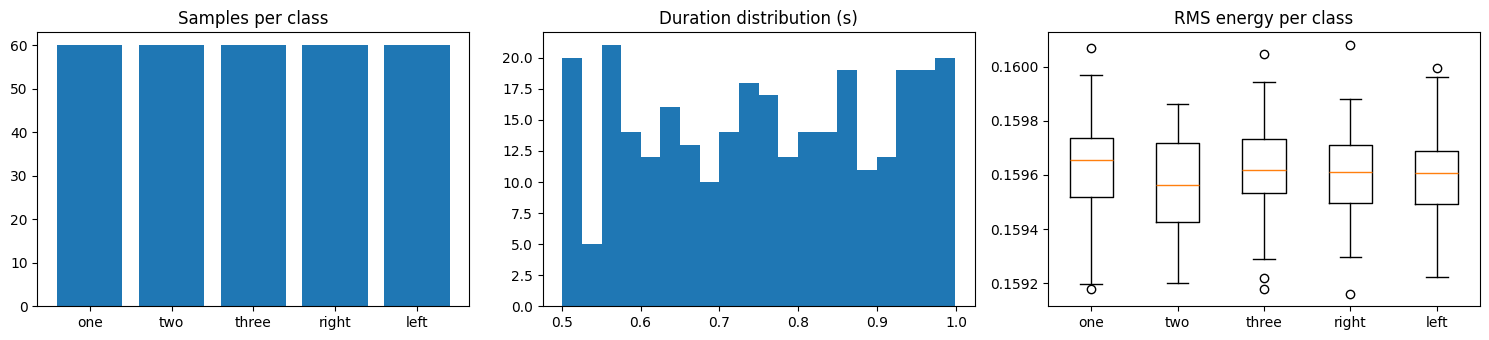

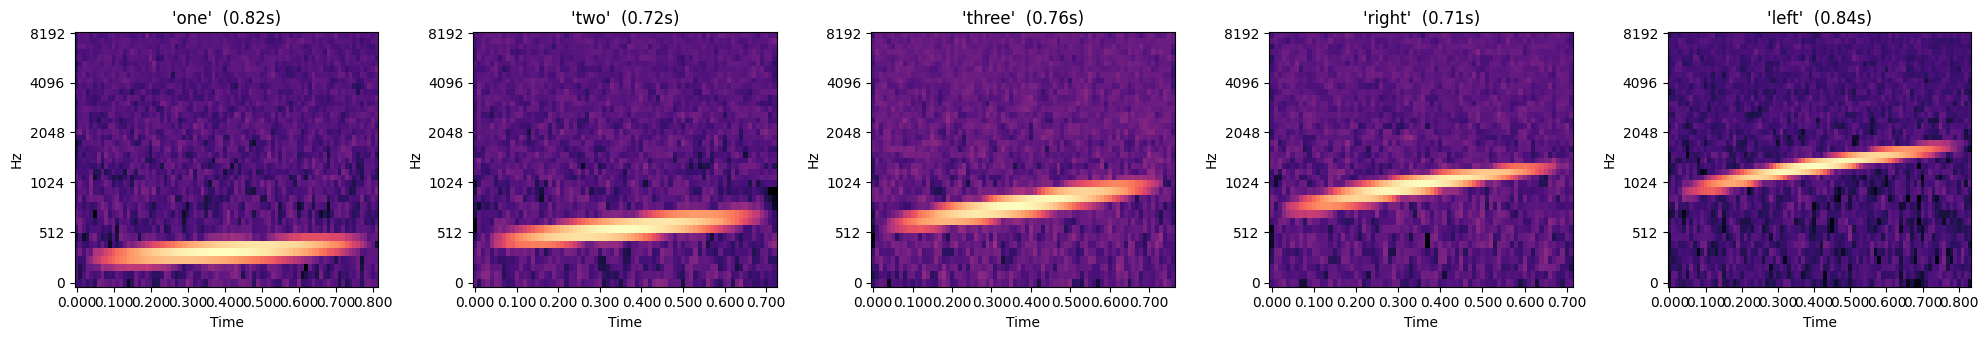

In [3]:
# ---------------- S1: data inspection ----------------
files, labels = [], []
for ci, c in enumerate(CLASSES):
    fs = sorted(glob.glob(os.path.join(DATA_DIR, c, "*.wav")))
    files += fs; labels += [ci] * len(fs)
labels = np.array(labels)

print("Samples per class:")
for ci, c in enumerate(CLASSES): print(f"  {c:6s}: {(labels == ci).sum()}")
print("Total:", len(files))

waves = [librosa.load(f, sr=SR, mono=True)[0] for f in files]
durations = np.array([len(w) / SR for w in waves])
rms = np.array([np.sqrt(np.mean(w ** 2)) for w in waves])
print(f"Duration (s): min={durations.min():.2f}, mean={durations.mean():.2f}, max={durations.max():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].bar(CLASSES, [(labels == i).sum() for i in range(5)]); ax[0].set_title("Samples per class")
ax[1].hist(durations, bins=20); ax[1].set_title("Duration distribution (s)")
ax[2].boxplot([rms[labels == i] for i in range(5)]); ax[2].set_xticklabels(CLASSES); ax[2].set_title("RMS energy per class")
plt.tight_layout(); plt.savefig("figures/data_analysis.png", dpi=150); plt.show()

# example log-mel spectrogram for each keyword
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ci, c in enumerate(CLASSES):
    idx = np.where(labels == ci)[0][0]
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=waves[idx], sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS), ref=np.max)
    librosa.display.specshow(S, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=axes[ci])
    axes[ci].set_title(f"'{c}'  ({durations[idx]:.2f}s)")
plt.tight_layout(); plt.savefig("figures/spectrograms.png", dpi=150); plt.show()

**Observation:** durations and energies vary across files and keywords; features are therefore normalised (training statistics) and padded/truncated to 101 frames.

## S2: Data splitting and feature extraction

In [4]:
# ---------------- S2: 70 / 15 / 15 stratified split ----------------
idx_all = np.arange(len(files))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=labels, random_state=SEED)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.50, stratify=labels[idx_tmp], random_state=SEED)
print("Train / Val / Test:", len(idx_tr), len(idx_va), len(idx_te))

# ---------------- S2: feature extraction (13 MFCC, 25 ms window, 10 ms hop) ----------------
def mfcc_feat(w):
    m = librosa.feature.mfcc(y=w, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    return m.T.astype(np.float32)                         # (frames, 13)

raw = [mfcc_feat(w) for w in waves]

# normalise with TRAINING-set statistics only
train_frames = np.concatenate([raw[i] for i in idx_tr], axis=0)
mu, sd = train_frames.mean(0), train_frames.std(0) + 1e-8

def pad_trunc(f, L=MAX_LEN):
    if len(f) >= L: return f[:L]
    return np.vstack([f, np.zeros((L - len(f), f.shape[1]), dtype=np.float32)])   # zero = training mean after normalisation

feats = np.stack([pad_trunc((f - mu) / sd) for f in raw])  # (N, T, D)
print("Feature tensor:", feats.shape, "(N, time steps, feature dim)")
D = feats.shape[2]

Train / Val / Test: 210 45 45
Feature tensor: (300, 101, 13) (N, time steps, feature dim)


## S3: Data loading

In [5]:
# ---------------- S3: Dataset + DataLoader ----------------
class KWSDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32); self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

BATCH = 32
train_dl = DataLoader(KWSDataset(feats[idx_tr], labels[idx_tr]), batch_size=BATCH, shuffle=True)
val_dl   = DataLoader(KWSDataset(feats[idx_va], labels[idx_va]), batch_size=BATCH)
test_dl  = DataLoader(KWSDataset(feats[idx_te], labels[idx_te]), batch_size=BATCH)
xb, yb = next(iter(train_dl)); print("Batch shape:", xb.shape, yb.shape)

Batch shape: torch.Size([32, 101, 13]) torch.Size([32])


## S4: Model design (Linear → LSTM → last hidden state → Linear)

In [6]:
class LSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden=64, n_classes=5):
        super().__init__()
        self.proj = nn.Linear(input_dim, hidden)                                   # D -> 64
        self.lstm = nn.LSTM(input_size=hidden, hidden_size=hidden, num_layers=1, batch_first=True)
        self.fc   = nn.Linear(hidden, n_classes)                                   # 64 -> 5
    def forward(self, x):                 # x: (batch, T, D)
        z = self.proj(x)                  # (batch, T, 64)
        _, (h_n, _) = self.lstm(z)        # h_n: (1, batch, 64) -> last hidden state h_T
        return self.fc(h_n[-1])           # logits

model = LSTMClassifier(D)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

LSTMClassifier(
  (proj): Linear(in_features=13, out_features=64, bias=True)
  (lstm): LSTM(64, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=5, bias=True)
)
Trainable parameters: 34501


## S5: Training

In [7]:
# ---------------- S5: training (10 epochs, Adam lr=1e-3, CrossEntropyLoss, batch 32) ----------------
EPOCHS = 10
model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(dl, train):
    model.train(train)
    tot_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)   # guards against exploding gradients
                optimizer.step()
            tot_loss += loss.item() * len(yb); correct += (logits.argmax(1) == yb).sum().item(); n += len(yb)
    return tot_loss / n, correct / n

hist = {"tr_loss": [], "tr_acc": [], "va_loss": [], "va_acc": []}
for ep in range(1, EPOCHS + 1):
    tl, ta = run_epoch(train_dl, True); vl, va = run_epoch(val_dl, False)
    for k, v in zip(hist, [tl, ta, vl, va]): hist[k].append(v)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")

Epoch  1/10 | train loss 1.6125 acc 0.1810 | val loss 1.6117 acc 0.1556
Epoch  2/10 | train loss 1.6094 acc 0.1810 | val loss 1.6103 acc 0.1556
Epoch  3/10 | train loss 1.6081 acc 0.2000 | val loss 1.6079 acc 0.1556
Epoch  4/10 | train loss 1.6065 acc 0.2048 | val loss 1.6060 acc 0.2222
Epoch  5/10 | train loss 1.6039 acc 0.2048 | val loss 1.6025 acc 0.2222
Epoch  6/10 | train loss 1.5953 acc 0.2286 | val loss 1.5940 acc 0.2889
Epoch  7/10 | train loss 1.5714 acc 0.2952 | val loss 1.5465 acc 0.3556
Epoch  8/10 | train loss 1.4864 acc 0.3905 | val loss 1.4193 acc 0.4889
Epoch  9/10 | train loss 1.3543 acc 0.5238 | val loss 1.2058 acc 0.5556
Epoch 10/10 | train loss 1.2171 acc 0.5286 | val loss 1.0866 acc 0.6222


## S6: Evaluation and visualization

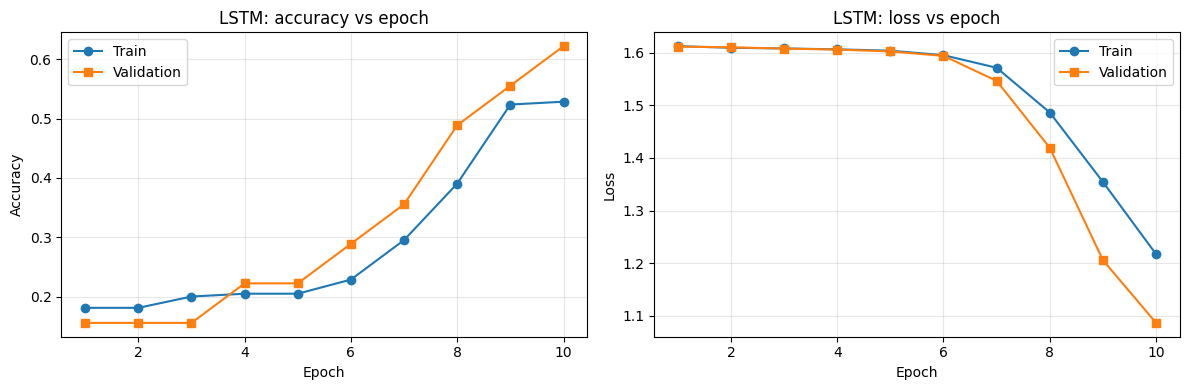

Final TEST accuracy: 55.56 %


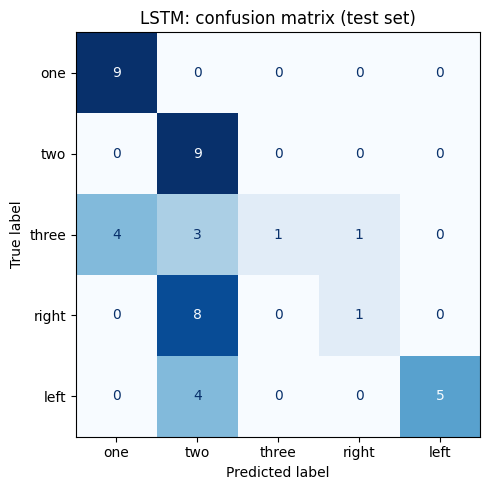

              precision    recall  f1-score   support

         one      0.692     1.000     0.818         9
         two      0.375     1.000     0.545         9
       three      1.000     0.111     0.200         9
       right      0.500     0.111     0.182         9
        left      1.000     0.556     0.714         9

    accuracy                          0.556        45
   macro avg      0.713     0.556     0.492        45
weighted avg      0.713     0.556     0.492        45



In [8]:
# ---------------- S6: accuracy curves ----------------
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, hist["tr_acc"], "o-", label="Train"); ax[0].plot(ep, hist["va_acc"], "s-", label="Validation")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].set_title("LSTM: accuracy vs epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, hist["tr_loss"], "o-", label="Train"); ax[1].plot(ep, hist["va_loss"], "s-", label="Validation")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].set_title("LSTM: loss vs epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/lstm_training_curves.png", dpi=150); plt.show()

# ---------------- S6: test accuracy + confusion matrix ----------------
model.eval(); preds, trues = [], []
with torch.no_grad():
    for xb, yb in test_dl:
        probs = torch.softmax(model(xb.to(device)), dim=1)        # class probabilities
        preds += probs.argmax(1).cpu().tolist(); trues += yb.tolist()
preds, trues = np.array(preds), np.array(trues)
print(f"Final TEST accuracy: {(preds == trues).mean() * 100:.2f} %")

cm = confusion_matrix(trues, preds, labels=range(5))
disp = ConfusionMatrixDisplay(cm, display_labels=CLASSES)
fig, ax = plt.subplots(figsize=(6, 5)); disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("LSTM: confusion matrix (test set)"); plt.tight_layout()
plt.savefig("figures/lstm_confusion_matrix.png", dpi=150); plt.show()
print(classification_report(trues, preds, target_names=CLASSES, digits=3))

### Discussion
* Compare these curves and the test accuracy with Part II: the LSTM's gated memory cell normally gives faster, more stable convergence and higher accuracy than the plain RNN on ~100-step sequences.
* Use the confusion matrix to identify which keywords are confused (e.g. *two*/*three*, *right*/*left* share similar acoustic segments).
* Possible improvements: more epochs, bidirectional LSTM, log-mel features, data augmentation (noise, time shift).